# NB-001 — How do we know an algorithm worked?

A program can finish, print something plausible, and still be wrong. This
investigation builds several kinds of evidence around two deliberately small
algorithms: insertion sort is the main object of study, while first-match
binary search shows why preconditions matter.

**Research question.** What combination of specification, invariant,
independent oracle, generated cases, and measurement gives defensible evidence
that an implementation satisfies its contract?

The notebook uses only synthetic integer sequences. It does not attempt a
sorting or searching survey; later notebooks own that work. Sources are cited by
the identifiers in `docs/SOURCES.md`, especially CLRS for invariants and
correctness [S005], Hypothesis for property-based search [S064], and Python and
pyperf documentation for measurement limits [S061, S063].

In [1]:
import gc
import inspect
import platform
import time
import tracemalloc
from bisect import bisect_left
from importlib.metadata import version

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from hypothesis import find, settings
from hypothesis import strategies as st
from IPython import get_ipython
from IPython.display import Code, display

from mydatalabnotes.algorithms import (
    binary_search_first,
    buggy_insertion_sort,
    insertion_sort,
    insertion_sort_trace,
    sorting_contract,
)
from mydatalabnotes.evidence import (
    canonical_json_sha256,
    exhaustive_integer_sequences,
)

In [3]:
SEED = 20261101
rng = np.random.default_rng(SEED)
get_ipython().run_line_magic("matplotlib", "inline")
pd.set_option("display.max_colwidth", 80)
plt.style.use("seaborn-v0_8-whitegrid")

In [4]:
environment = pd.Series({
    "python": platform.python_version(),
    "platform": f"{platform.system()} {platform.release()} ({platform.machine()})",
    "numpy": version("numpy"),
    "pandas": version("pandas"),
    "matplotlib": version("matplotlib"),
    "hypothesis": version("hypothesis"),
    "seed": SEED,
}, name="recorded environment")
environment.to_frame()

,recorded environment
python,3.12.13
platform,Windows 11 (AMD64)
numpy,2.5.4
pandas,3.1.0
matplotlib,3.11.2
hypothesis,6.170.14
seed,20261101


The version table is evidence about this execution, not a claim that every
version produces byte-identical output. The seed fixes the NumPy generator used
below for this recorded implementation [S062]. Hypothesis is separately run with
a deterministic profile and no example database.

## 1. Correctness needs a contract

For a finite input sequence $x$, an algorithm is **partially correct** when:

$$
P(x) \land \text{termination} \implies Q(x, y),
$$

where $P$ is the precondition and $Q$ the postcondition. **Total
correctness** additionally establishes termination for inputs satisfying
$P$. Operational correctness also includes the representation, exception, and
resource behavior promised by the interface. A fast result outside the contract
is not a correct result.

In [5]:
contract = pd.DataFrame([
    ("Input", "A finite Python sequence whose elements are integers"),
    ("Output", "A new list; the input object is not mutated"),
    ("Order", "result[i] <= result[i + 1] for every valid i"),
    ("Content", "result and input have the same integer multiset"),
    ("Termination", "The finite outer index advances; the inner index decreases"),
    ("Invalid input", "Raise TypeError rather than silently coerce values"),
], columns=["contract part", "NB-001 requirement"])
contract

,contract part,NB-001 requirement
0,Input,A finite Python sequence whose elements are integers
1,Output,A new list; the input object is not mutated
2,Order,result[i] <= result[i + 1] for every valid i
3,Content,result and input have the same integer multiset
4,Termination,The finite outer index advances; the inner index decreases
5,Invalid input,Raise TypeError rather than silently coerce values


“Looks sorted” is only one postcondition. A routine that returns an empty list is
nondecreasing but loses every input value. That is why the order and multiset
clauses are checked independently. Stability is not part of this integer-only
experiment's public contract; later sorting work can introduce tagged records
and test it explicitly.

## 2. Trace one implementation and its invariant

Insertion sort is useful here because its state is small enough to inspect. At
the start of outer iteration $i$, the prefix before $i$ is sorted and is a
permutation of the original prefix. The step inserts one key into that prefix.
This is a loop invariant in the standard initialization–maintenance–termination
proof pattern [S005].

In [6]:
display(Code(inspect.getsource(insertion_sort), language="python"))

def insertion_sort(values: Sequence[int]) -> list[int]:
    """Return a stable, nondecreasing copy of a finite integer sequence."""
    result = _integer_list(values)
    for outer in range(1, len(result)):
        key = result[outer]
        cursor = outer - 1
        while cursor >= 0 and result[cursor] > key:
            result[cursor + 1] = result[cursor]
            cursor -= 1
        result[cursor + 1] = key
    return result

In [7]:
hand_input = [5, 2, 4, 2]
hand_result, hand_trace = insertion_sort_trace(hand_input)
trace_frame = pd.DataFrame(hand_trace)
trace_frame

,outer,key,comparisons,shifts,state,sorted_prefix
0,1,2,1,1,"(2, 5, 4, 2)","(2, 5)"
1,2,4,2,1,"(2, 4, 5, 2)","(2, 4, 5)"
2,3,2,3,2,"(2, 2, 4, 5)","(2, 2, 4, 5)"


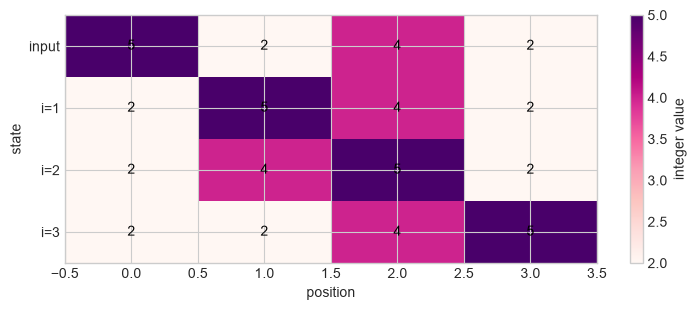

In [8]:
states = [tuple(hand_input), *trace_frame["state"]]
fig, ax = plt.subplots(figsize=(7.5, 3.2))
image = ax.imshow(np.array(states), cmap="RdPu", aspect="auto")
for row, state in enumerate(states):
    for column, value in enumerate(state):
        ax.text(column, row, value, ha="center", va="center", color="black")
ax.set(xlabel="position", ylabel="state", yticks=range(len(states)))
ax.set_yticklabels(["input", *[f"i={i}" for i in trace_frame["outer"]]])
fig.colorbar(image, ax=ax, label="integer value")
fig.tight_layout()
display(fig)
plt.close(fig)

The table and state image expose every outer transition. Duplicate `2` values
remain present, and the shaded prefix grows from the left without requiring us
to infer hidden state. For this input, the last state is nondecreasing, but the
postconditions still need explicit checks.

In [9]:
hand_evidence = pd.Series(
    sorting_contract(hand_input, hand_result), name="observed postconditions"
)
hand_evidence.to_frame()

,observed postconditions
nondecreasing,True
same_multiset,True
same_length,True
all_postconditions,True


Every observed postcondition is true for the hand example. This is useful
evidence and a readable trace, but it does not establish correctness for all
valid sequences.

## 3. Boundary cases and independent oracles

We next separate examples chosen for meaning from generated cases chosen for
coverage. Python's `sorted` is an independent implementation oracle for these
integer inputs; it is not a proof of our code, but disagreement is decisive
evidence that at least one implementation or contract interpretation is wrong.

In [10]:
boundary_inputs = [[], [7], [2, 2, 2], [-3, 0, -3], [1, 2, 3], [3, 2, 1]]
boundary_rows = [
    {"input": values, "result": insertion_sort(values),
     "reference": sorted(values),
     "contract": sorting_contract(
         values, insertion_sort(values)
     )["all_postconditions"]}
    for values in boundary_inputs
]
pd.DataFrame(boundary_rows)

,input,result,reference,contract
0,[],[],[],True
1,[7],[7],[7],True
2,"[2, 2, 2]","[2, 2, 2]","[2, 2, 2]",True
3,"[-3, 0, -3]","[-3, -3, 0]","[-3, -3, 0]",True
4,"[1, 2, 3]","[1, 2, 3]","[1, 2, 3]",True
5,"[3, 2, 1]","[1, 2, 3]","[1, 2, 3]",True


In [11]:
invalid_inputs = [[1.0], [True], [1, None], "321"]
invalid_rows = []
for values in invalid_inputs:
    try:
        insertion_sort(values)
        outcome = "accepted"
    except Exception as error:
        outcome = f"{type(error).__name__}: {error}"
    invalid_rows.append({"input": repr(values), "observed": outcome})
pd.DataFrame(invalid_rows)

,input,observed
0,[1.0],TypeError: every value must be an integer
1,[True],TypeError: every value must be an integer
2,"[1, None]",TypeError: every value must be an integer
3,'321',TypeError: values must be a finite sequence of integers


In [12]:
tiny_cases = exhaustive_integer_sequences((-1, 0, 1), max_length=6)
tiny_failures = [
    values for values in tiny_cases if insertion_sort(values) != sorted(values)
]
pd.Series({
    "exhaustive cases": len(tiny_cases),
    "domain": "{-1, 0, 1}",
    "maximum length": 6,
    "failures": len(tiny_failures),
}, name="finite-domain evidence").to_frame()

,finite-domain evidence
exhaustive cases,1093
domain,"{-1, 0, 1}"
maximum length,6
failures,0


The empty input, duplicates, negative values, sorted and reverse-ordered cases
satisfy the same contract. Invalid values fail visibly instead of being coerced.
Exhaustive agreement covers all 1,093 sequences in the declared tiny domain. It
is complete evidence for that finite domain only; integers of other magnitudes
and longer sequences remain outside this enumeration.

## 4. Preconditions are observable behavior

First-match binary search demonstrates a different failure mode. Its guarantee
depends on nondecreasing, random-access input. If that precondition is omitted,
a returned index can look plausible while having no valid interpretation.

In [13]:
display(Code(inspect.getsource(binary_search_first), language="python"))

def binary_search_first(values: Sequence[int], target: int) -> int:
    """Return the first matching index in sorted values, or -1 when absent."""
    sequence = _integer_list(values)
    if type(target) is not int:
        raise TypeError("target must be an integer")
    if any(left > right for left, right in zip(sequence, sequence[1:], strict=False)):
        raise ValueError("binary_search_first requires nondecreasing input")

    low, high = 0, len(sequence)
    while low < high:
        middle = (low + high) // 2
        if sequence[middle] < target:
            low = middle + 1
        else:
            high = middle
    return low if low < len(sequence) and sequence[low] == target else -1

In [14]:
search_cases = [([], 2), ([1], 1), ([1, 1, 2, 5], 1), ([1, 3, 5], 4)]
search_rows = []
for values, target in search_cases:
    reference = bisect_left(values, target)
    expected = (
        reference
        if reference < len(values) and values[reference] == target
        else -1
    )
    search_rows.append({
        "values": values, "target": target,
        "observed": binary_search_first(values, target), "reference": expected,
    })
pd.DataFrame(search_rows)

,values,target,observed,reference
0,[],2,-1,-1
1,[1],1,0,0
2,"[1, 1, 2, 5]",1,0,0
3,"[1, 3, 5]",4,-1,-1


In [15]:
try:
    binary_search_first([3, 1, 2], 1)
    precondition_outcome = "unexpectedly accepted"
except ValueError as error:
    precondition_outcome = f"controlled rejection: {error}"
pd.Series({"unsorted input": [3, 1, 2], "outcome": precondition_outcome})

unsorted input                                                                 [3, 1, 2]
outcome           controlled rejection: binary_search_first requires nondecreasing input
dtype: object

The duplicate case returns the first matching index, and the absent case returns
`-1`, matching the `bisect_left`-based oracle. The unsorted sequence is rejected
before search. Rejecting an invalid domain is part of correctness; quietly
searching it would weaken the contract.

## 5. Can the tests expose a plausible defect?

A validation method that passes correct code is not enough. It should also fail
code with a realistic defect. The next variant changes `cursor >= 0` to
`cursor > 0`, so the smallest element cannot move past position zero.

In [16]:
display(Code(inspect.getsource(buggy_insertion_sort), language="python"))

def buggy_insertion_sort(values: Sequence[int]) -> list[int]:
    """Deliberately defective variant: index zero is never shifted."""
    result = _integer_list(values)
    for outer in range(1, len(result)):
        key = result[outer]
        cursor = outer - 1
        while cursor > 0 and result[cursor] > key:
            result[cursor + 1] = result[cursor]
            cursor -= 1
        result[cursor + 1] = key
    return result

In [17]:
defect_rng = np.random.default_rng(SEED)
randomized_counterexample = None
for _attempt in range(1, 501):
    length = int(defect_rng.integers(0, 9))
    candidate = defect_rng.integers(-5, 6, size=length).tolist()
    if buggy_insertion_sort(candidate) != sorted(candidate):
        randomized_counterexample = candidate
        attempt = _attempt
        break
pd.Series({
    "deterministic randomized cases examined": attempt,
    "first counterexample": randomized_counterexample,
})

deterministic randomized cases examined                1
first counterexample                       [1, 3, -2, 0]
dtype: object

In [18]:
integer_lists = st.lists(st.integers(-3, 3), min_size=0, max_size=6)
minimal_counterexample = find(
    integer_lists,
    lambda values: buggy_insertion_sort(values) != sorted(values),
    settings=settings(
        max_examples=2_000, derandomize=True, database=None, deadline=None
    ),
)
print(f"Minimal counterexample: {minimal_counterexample}")

Minimal counterexample: [0, -1]


In [19]:
defect_comparison = pd.DataFrame({
    "implementation": [
        "reference sorted", "correct insertion", "defective insertion"
    ],
    "result": [
        sorted(minimal_counterexample),
        insertion_sort(minimal_counterexample),
        buggy_insertion_sort(minimal_counterexample),
    ],
})
defect_comparison

,implementation,result
0,reference sorted,"[-1, 0]"
1,correct insertion,"[-1, 0]"
2,defective insertion,"[0, -1]"


In [20]:
defect_cases = exhaustive_integer_sequences((-1, 0, 1), max_length=5)
defect_rates = []
for length in range(6):
    cases = [values for values in defect_cases if len(values) == length]
    failures = sum(
        buggy_insertion_sort(values) != sorted(values) for values in cases
    )
    defect_rates.append(
        {"length": length, "cases": len(cases), "failures": failures}
    )
defect_frame = pd.DataFrame(defect_rates)
defect_frame["failure rate"] = defect_frame["failures"] / defect_frame["cases"]
defect_frame

,length,cases,failures,failure rate
0,0,1,0,0.000000
1,1,3,0,0.000000
2,2,9,3,0.333333
3,3,27,13,0.481481
4,4,81,45,0.555556
5,5,243,145,0.596708


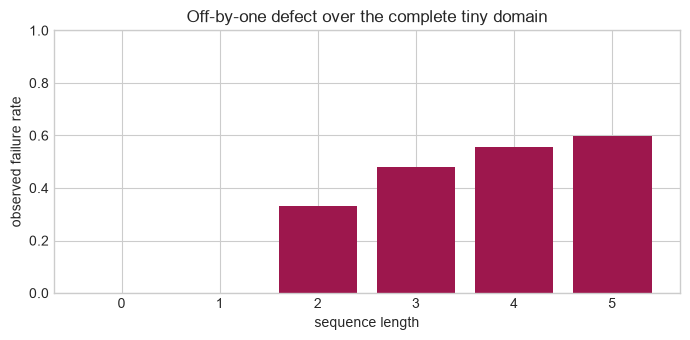

In [21]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(defect_frame["length"], defect_frame["failure rate"], color="#9d174d")
ax.set(xlabel="sequence length", ylabel="observed failure rate", ylim=(0, 1))
ax.set_title("Off-by-one defect over the complete tiny domain")
fig.tight_layout()
display(fig)
plt.close(fig)

The seeded search finds a reproducible failure, while Hypothesis shrinks the
failure to a smaller counterexample [S064]. The exhaustive plot explains why a
handful of happy-path examples could miss the defect: some inputs still happen
to work. Property-based generation is a search strategy, not a proof of an
arbitrary program (R0 claim C029).

## 6. Metamorphic relations add checks when exact answers are inconvenient

For integer sorting, adding the same offset to every input should add that
offset to every sorted output without changing order. Sorting an already sorted
result should also leave it unchanged. These relations compare executions
without needing a new expected list for every case.

In [22]:
metamorphic_rng = np.random.default_rng(SEED + 1)
metamorphic_rows = []
for case_id in range(200):
    values = metamorphic_rng.integers(-100, 101, size=20).tolist()
    offset = int(metamorphic_rng.integers(-20, 21))
    result = insertion_sort(values)
    translated = insertion_sort([value + offset for value in values])
    metamorphic_rows.append({
        "case": case_id,
        "translation": translated == [value + offset for value in result],
        "idempotence": insertion_sort(result) == result,
    })
metamorphic_frame = pd.DataFrame(metamorphic_rows)

In [23]:
pd.Series({
    "metamorphic cases": len(metamorphic_frame),
    "translation failures": int((~metamorphic_frame["translation"]).sum()),
    "idempotence failures": int((~metamorphic_frame["idempotence"]).sum()),
}, name="metamorphic evidence").to_frame()

,metamorphic evidence
metamorphic cases,200
translation failures,0
idempotence failures,0


Both relations hold for the 200 generated cases. They complement the exact
oracle, but they are not sufficient by themselves: a function that always
returned an empty list would satisfy both relations. Evidence quality comes
from independent and differently fallible checks, not from the number of green
rows.

## 7. Deterministic work and variable measurements

Correctness results above are deterministic for the declared inputs. Wall-clock
measurements are observations influenced by the interpreter, operating system,
caches, and other activity [S061, S063]. We therefore compare operation counts
separately from repeated elapsed-time batches.

In [24]:
count_rows = []
for size in [8, 16, 32, 64, 128]:
    values = list(range(size, 0, -1))
    _, trace = insertion_sort_trace(values)
    count_rows.append({
        "n": size,
        "comparisons": sum(step["comparisons"] for step in trace),
        "shifts": sum(step["shifts"] for step in trace),
        "n squared": size**2,
    })
count_frame = pd.DataFrame(count_rows)
count_frame

,n,comparisons,shifts,n squared
0,8,28,28,64
1,16,120,120,256
2,32,496,496,1024
3,64,2016,2016,4096
4,128,8128,8128,16384


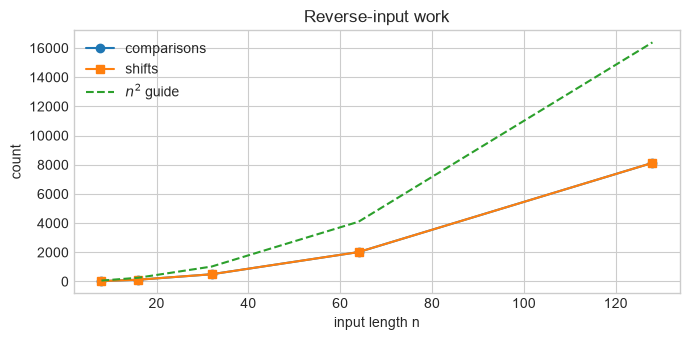

In [25]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(count_frame["n"], count_frame["comparisons"], "o-", label="comparisons")
ax.plot(count_frame["n"], count_frame["shifts"], "s-", label="shifts")
ax.plot(count_frame["n"], count_frame["n squared"], "--", label=r"$n^2$ guide")
ax.set(xlabel="input length n", ylabel="count", title="Reverse-input work")
ax.legend()
fig.tight_layout()
display(fig)
plt.close(fig)

In [26]:
workloads = {
    "ordered": list(range(96)),
    "seeded random": np.random.default_rng(SEED).integers(-500, 501, 96).tolist(),
    "reversed": list(range(95, -1, -1)),
}
timing_rng = np.random.default_rng(SEED + 2)
timing_rows = []
for batch in range(25):
    for name in timing_rng.permutation(list(workloads)):
        gc.disable()
        started = time.perf_counter_ns()
        for _ in range(40):
            insertion_sort(workloads[name])
        elapsed = (time.perf_counter_ns() - started) / 40_000_000
        gc.enable()
        timing_rows.append(
            {"batch": batch, "workload": name, "milliseconds": elapsed}
        )
timing_frame = pd.DataFrame(timing_rows)

In [27]:
timing_summary = timing_frame.groupby("workload")["milliseconds"].agg(
    batches="count", median="median", minimum="min", maximum="max"
)
timing_summary.round(4)

,batches,median,minimum,maximum
workload,,,,
ordered,25,0.0224,0.0219,0.0257
reversed,25,0.5789,0.5703,0.5940
seeded random,25,0.2786,0.2756,0.2906


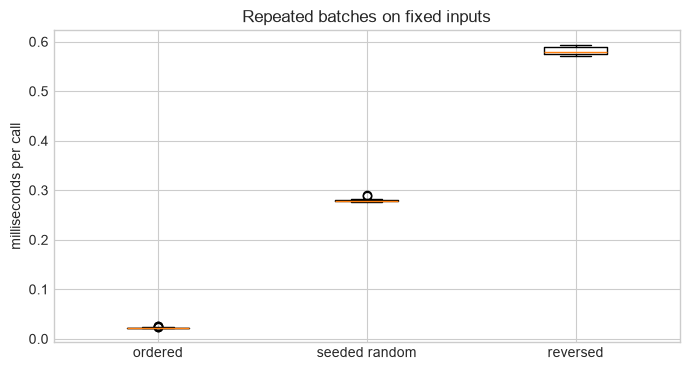

In [28]:
names = list(workloads)
samples = [
    timing_frame.loc[timing_frame["workload"] == name, "milliseconds"]
    for name in names
]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.boxplot(samples, tick_labels=names, showfliers=True)
ax.set(ylabel="milliseconds per call", title="Repeated batches on fixed inputs")
fig.tight_layout()
display(fig)
plt.close(fig)

In [29]:
tracemalloc.start()
insertion_sort(workloads["reversed"] * 8)
current_bytes, peak_bytes = tracemalloc.get_traced_memory()
tracemalloc.stop()
pd.Series({
    "current traced bytes": current_bytes,
    "peak traced bytes": peak_bytes,
    "scope": "Python allocations visible to tracemalloc; not process RSS",
}, name="bounded allocation observation").to_frame()

,bounded allocation observation
current traced bytes,1093
peak traced bytes,19606
scope,Python allocations visible to tracemalloc; not process RSS


The reverse-input comparison and shift counts are exact for this implementation
and input family. The elapsed-time batches vary even though their inputs and
outputs are fixed. The timing figure therefore describes this recorded process,
not a universal ranking or production forecast. The allocation observation is
similarly narrow: `tracemalloc` does not report every native or process-level
allocation. The external notebook runner records wall time and peak process-tree
RSS for the complete fresh-kernel execution.

## 8. Evidence ledger

In [30]:
ledger = pd.DataFrame([
    ("Hand trace", "Invariant and transitions are visible", "One input"),
    ("Boundary examples", "Named edge cases meet the contract", "Not exhaustive"),
    ("Independent oracle", "Two implementations agree", "Shared error possible"),
    ("Exhaustive tiny domain", "All 1,093 cases agree", "Finite domain only"),
    ("Seeded random", "Reproducible broad sampling", "Rare defects may remain"),
    ("Property search", "Finds and shrinks a real defect", "Search is not proof"),
    ("Metamorphic relations", "Two cross-run relations hold", "Relations are weak"),
    ("Timing batches", "Shows measured variability", "No scaling proof"),
], columns=["evidence", "what it establishes", "what it does not establish"])
ledger

,evidence,what it establishes,what it does not establish
0,Hand trace,Invariant and transitions are visible,One input
1,Boundary examples,Named edge cases meet the contract,Not exhaustive
2,Independent oracle,Two implementations agree,Shared error possible
3,Exhaustive tiny domain,"All 1,093 cases agree",Finite domain only
4,Seeded random,Reproducible broad sampling,Rare defects may remain
5,Property search,Finds and shrinks a real defect,Search is not proof
6,Metamorphic relations,Two cross-run relations hold,Relations are weak
7,Timing batches,Shows measured variability,No scaling proof


In [31]:
manifest = pd.Series({
    "notebook_id": "NB-001",
    "schema": "mydatalabnotes.experiment.v1",
    "profile": "quick",
    "seed": SEED,
    "synthetic_domain": "finite integer sequences",
    "tiny_domain_sha256": canonical_json_sha256(tiny_cases),
    "oracle": "Python sorted / bisect_left",
    "timer": "time.perf_counter_ns",
    "memory": "tracemalloc in notebook; process-tree RSS in runner",
    "correctness_tolerance": "exact integer equality",
}, name="experiment manifest")
manifest.to_frame()

,experiment manifest
notebook_id,NB-001
schema,mydatalabnotes.experiment.v1
profile,quick
seed,20261101
synthetic_domain,finite integer sequences
tiny_domain_sha256,afe4b98810b3c48d2a6745883d678e238b2fe43e74a64e73cd785bcf58b046fa
oracle,Python sorted / bisect_left
timer,time.perf_counter_ns
memory,tracemalloc in notebook; process-tree RSS in runner
correctness_tolerance,exact integer equality


## Synthesis: what the evidence establishes — and what it does not establish

The experiments establish that the reviewed implementation satisfies its stated
sorting contract for every sequence in the tiny exhaustive domain, all named
boundary cases, and the deterministic generated cases used here. The loop trace
is consistent with the sorted-prefix invariant. Independent reference checks,
metamorphic relations, and the ability to expose and minimize an injected defect
make the evidence more credible than a single example or a green execution log.

The central limitation is scope. These results do **not** prove the Python
interpreter, reference implementations, hardware,
or notebook runner correct. They do not establish correctness for unbounded
inputs, non-integer types, concurrent mutation, or resource exhaustion. Nor do
the timing observations predict another machine or make insertion sort a good
large-input choice. A mathematical proof and empirical testing answer different
questions; good engineering uses both while naming their assumptions.

NB-002 and NB-004 remain planned and unimplemented. This notebook is the complete
R1 boundary for the current assignment.